# 12 — AMX ablations: what does AMX contribute?

**Objective.** Replace two inferences of the earlier notebooks by measurements: that AMX is what lets vLLM scale (notebook 06) and that
llama.cpp's AMX path is inefficient (notebook 08, section 3).

**Research questions.**
1. (T3.1) What do the vLLM ablation levels really switch off, and how do throughput and scaling change without AMX?
2. (T3.2) Does llama.cpp's AMX build run Q8_0 prompt processing faster than its AVX-512 build, and how much of the AMX roof does it reach?

**Data.** `online/amx-ablation-verify` (short points per vLLM level with `ONEDNN_VERBOSE=profile_create`: `EXE.AMX_BUSY` and the oneDNN
implementations created) and `offline/amx-build` (llama-bench prompt processing of Q8_0, 8B, prompt lengths 128, 512, 4096, 8192; AMX build and
AVX-512 build, order amx, avx512, amx, avx512 inside one job, three llama-bench samples per cell). The two llama.cpp builds are configured
identically except `GGML_AMX_TILE/INT8/BF16` (`build-avx512/CMakeCache.txt`).

**Method.** The ratio AMX ÷ AVX-512 is formed inside each pass pair. Arithmetic rates use the operation model of notebook 10 (modelled operations per prompt
token × tokens/s) and are compared with the measured AMX INT8 GEMM roof. `EXE.AMX_BUSY` ÷ cycles is read from the telemetry samples in which the server cores
were busy.

**Assumptions.** llama-bench times forward passes only (no server). Prompt processing is the phase in which AMX can help most; decode and batched serving were not run
with the AVX-512 build.

In [1]:
import pandas as pd
from IPython.display import display

from llm_backend_analysis import paths
from llm_backend_analysis.analysis import amx, roofline
from llm_backend_analysis.data import loaders, registry
from llm_backend_analysis.reporting import Claim, claims_table, export_table, num, pct, rng, show, table, x
from llm_backend_analysis.visualization import plots, theme
from llm_backend_analysis.visualization.export import export_figure

theme.setup_notebook()
NOTEBOOK = "12_amx_ablations.ipynb"
compute = roofline.compute_ceilings(loaders.hardware_ceilings())

## 1. What do the vLLM ablation levels switch off?

`ONEDNN_MAX_CPU_ISA=AVX512_CORE_BF16` caps oneDNN's GEMMs below AMX, but vLLM also has its own AMX code (an attention kernel and small-weight linear kernels) that
does not look at that variable; it asks `torch.cpu._is_amx_tile_supported()`. Level `noamx_all` makes torch answer False. Each level was run for one short balanced
(512→512) point at C = 1 and C = 8.

In [2]:
ver = amx.verify_table(paths.RAW / "online" / "amx-ablation-verify" / "amx_verify.json")
display(table(ver.rename(columns={"level": "Level", "concurrency": "C", "status": "Status", "amx_busy_frac": "EXE.AMX_BUSY ÷ cycles",
                                  "no_amx_shim_active": "torch reports no AMX", "matmul_implementations": "oneDNN matmul implementations created",
                                  "amx_primitives": "AMX primitives"}),
              {"EXE.AMX_BUSY ÷ cycles": "{:.4%}"}, align="left"))
v = ver.set_index(["level", "concurrency"])
show(f"With AMX allowed vLLM's oneDNN matmuls are `brg_matmul:avx10_1_512_amx` and the AMX unit is busy {pct(v.loc[('amx', 1), 'amx_busy_frac'], 2, False)} (C = 1) to "
     f"{pct(v.loc[('amx', 8), 'amx_busy_frac'], 2, False)} (C = 8) of the cycles. Capping oneDNN removes every AMX matmul "
     f"(`brg_matmul:avx512_core_bf16`) and cuts the busy fraction by {pct(1 - v.loc[('noamx_gemm', 8), 'amx_busy_frac'] / v.loc[('amx', 8), 'amx_busy_frac'], 1, False)} at C = 8, "
     f"but not to zero ({pct(v.loc[('noamx_gemm', 8), 'amx_busy_frac'], 3, False)}): what remains is vLLM's own AMX code. With torch also reporting no AMX the counter reads "
     f"{pct(v.loc[('noamx_all', 8), 'amx_busy_frac'], 1, False)} at both C.")

Level,C,Status,EXE.AMX_BUSY ÷ cycles,torch reports no AMX,oneDNN matmul implementations created,AMX primitives
amx,1,ok,0.4895%,False,brg_matmul:avx10_1_512_amx ×14,14
amx,8,ok,1.9580%,False,brg_matmul:avx10_1_512_amx ×81,81
noamx_gemm,1,ok,0.0068%,False,brg_matmul:avx512_core_bf16 ×14,0
noamx_gemm,8,ok,0.0206%,False,brg_matmul:avx512_core_bf16 ×77,0
noamx_all,1,ok,0.0000%,True,brg_matmul:avx512_core_bf16 ×14,0
noamx_all,8,ok,0.0000%,True,brg_matmul:avx512_core_bf16 ×73,0


With AMX allowed vLLM's oneDNN matmuls are `brg_matmul:avx10_1_512_amx` and the AMX unit is busy 0.49% (C = 1) to 1.96% (C = 8) of the cycles. Capping oneDNN removes every AMX matmul (`brg_matmul:avx512_core_bf16`) and cuts the busy fraction by 98.9% at C = 8, but not to zero (0.021%): what remains is vLLM's own AMX code. With torch also reporting no AMX the counter reads 0.0% at both C.

**Interpretation.** `noamx_gemm` is the setting of the review but leaves a small AMX residue; `noamx_all` is a complete AMX ablation for the BF16 paths that matter here
(the counter is exactly zero). Comparing the two levels apportions any loss between oneDNN's GEMMs and vLLM's own AMX kernels.

## 2. llama.cpp Q8_0: AMX build vs AVX-512 build (prompt processing)

Does the AMX path of llama.cpp make prompt processing faster at all, and by how much?

Prompt tokens,AVX-512 build tok/s,AMX build tok/s,AMX ÷ AVX-512,pair min,pair max,AVX-512 ÷ AMX INT8 roof,AMX build ÷ AMX INT8 roof,"AMX busy, AVX-512 build","AMX busy, AMX build"
128,241,364,1.51×,1.50×,1.51×,3.8%,5.8%,0.00%,3.99%
512,217,426,1.96×,1.94×,1.98×,3.5%,6.8%,0.00%,4.56%
4096,186,454,2.44×,2.43×,2.44×,3.2%,7.7%,0.00%,5.14%
8192,170,349,2.05×,2.05×,2.06×,3.1%,6.4%,0.00%,4.12%


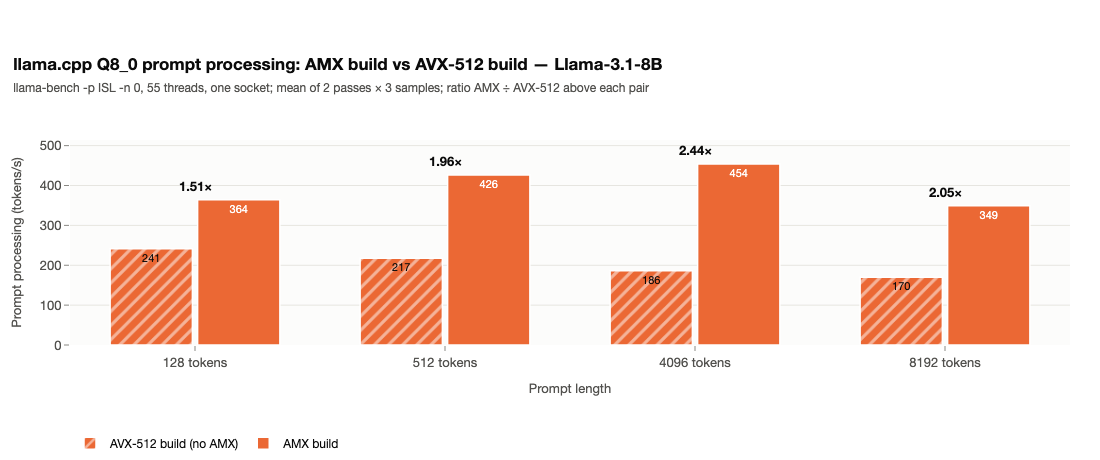

The AMX build processes prompts 1.51×–2.44× as fast as the AVX-512 build (largest at 4096 tokens); the ratio of a pass pair stays within ±0.8% of the mean. The AMX unit is busy 4.0%–5.1% of the cycles with the AMX build and 0.0% with the AVX-512 build. The AMX build reaches 5.8%–7.7% of the measured AMX INT8 GEMM roof (88.3 TOP/s), the AVX-512 build 3.1%–3.8%.

In [3]:
samples = loaders.offline_samples(campaign="amx-build")
cmp = amx.build_comparison(samples, compute)
busy = amx.offline_amx_busy(paths.RAW / "telemetry", "amx-build").groupby(["workload", "build"])["amx_busy_frac"].mean().unstack()
cmp = cmp.merge(busy.rename(columns={"amx": "amx_busy_amx_build", "avx512": "amx_busy_avx512_build"}), left_on="workload", right_index=True)
display(table(cmp[["isl", "avx512_tok_s", "amx_tok_s", "ratio", "ratio_min", "ratio_max", "avx512_share_of_roof", "amx_share_of_roof",
                   "amx_busy_avx512_build", "amx_busy_amx_build"]]
              .rename(columns={"isl": "Prompt tokens", "avx512_tok_s": "AVX-512 build tok/s", "amx_tok_s": "AMX build tok/s", "ratio": "AMX ÷ AVX-512",
                               "ratio_min": "pair min", "ratio_max": "pair max", "avx512_share_of_roof": "AVX-512 ÷ AMX INT8 roof",
                               "amx_share_of_roof": "AMX build ÷ AMX INT8 roof", "amx_busy_avx512_build": "AMX busy, AVX-512 build",
                               "amx_busy_amx_build": "AMX busy, AMX build"}),
              {"AVX-512 build tok/s": "{:.0f}", "AMX build tok/s": "{:.0f}", "AMX ÷ AVX-512": "{:.2f}×", "pair min": "{:.2f}×", "pair max": "{:.2f}×",
               "AVX-512 ÷ AMX INT8 roof": "{:.1%}", "AMX build ÷ AMX INT8 roof": "{:.1%}", "AMX busy, AVX-512 build": "{:.2%}",
               "AMX busy, AMX build": "{:.2%}"}))
fig = plots.build_comparison_figure(cmp, title="llama.cpp Q8_0 prompt processing: AMX build vs AVX-512 build — Llama-3.1-8B",
                                    subtitle="llama-bench -p ISL -n 0, 55 threads, one socket; mean of 2 passes × 3 samples; ratio AMX ÷ AVX-512 above each pair")
fig.show()
export_figure(fig, "amx_build_prompt_processing", source=NOTEBOOK,
              caption="llama.cpp Q8_0 (8B) prompt processing with the AMX build (solid) and the AVX-512 build (hatched), by prompt length; ratio above each pair.")
export_table(cmp, "amx_build_comparison")
show(f"The AMX build processes prompts {rng(cmp['ratio'], x, nd=2)} as fast as the AVX-512 build (largest at {int(cmp.loc[cmp['ratio'].idxmax(), 'isl'])} tokens); the ratio of a pass "
     f"pair stays within ±{pct(max((cmp['ratio_min'] / cmp['ratio'] - 1).abs().max(), (cmp['ratio_max'] / cmp['ratio'] - 1).abs().max()), 1, False)} of the mean. "
     f"The AMX unit is busy {rng(cmp['amx_busy_amx_build'], lambda v: pct(v, 1, False))} of the cycles with the AMX build and {pct(cmp['amx_busy_avx512_build'].max(), 1, False)} with the AVX-512 build. "
     f"The AMX build reaches {rng(cmp['amx_share_of_roof'], lambda v: pct(v, 1, False))} of the measured AMX INT8 GEMM roof ({num(cmp['roof_tops'].iloc[0], 1)} TOP/s), the AVX-512 build "
     f"{rng(cmp['avx512_share_of_roof'], lambda v: pct(v, 1, False))}.")

**Interpretation.** *Measured:* llama.cpp's AMX path is effective in the sense that it makes Q8_0 prompt processing 1.5–2.4× faster than the AVX-512 kernels of the same engine,
and the effect grows with the prompt length where more rows fill the tiles. *Also measured:* it uses little of what the hardware offers, a few percent of the AMX INT8 GEMM roof with the
AMX unit busy only 4–5% of the cycles, so the AMX build lifts the engine from AVX-512 level but not to the hardware's level (the correction of notebook 08, section 3, stands:
"AMX available" is not "AMX used efficiently"). *Not measured here:* the reason (tile loading, packing, thread scaling) and the effect on decode or batched serving.

In [4]:
claims = [
    Claim("The AMX build is faster than the AVX-512 build at every prompt length", bool((cmp["ratio"] > 1).all()), rng(cmp["ratio"], x, nd=2)),
    Claim("The AMX build keeps the AMX unit busy; the AVX-512 build does not touch it",
          bool((cmp["amx_busy_amx_build"] > 0.01).all() and (cmp["amx_busy_avx512_build"] < 0.001).all()),
          f"AMX build {rng(cmp['amx_busy_amx_build'], lambda v: pct(v, 1, False))}, AVX-512 build {pct(cmp['amx_busy_avx512_build'].max(), 2, False)}"),
    Claim("Both passes agree: the ratio of each pass pair is within 3% of the mean", bool(((cmp["ratio_max"] - cmp["ratio_min"]) / cmp["ratio"] < 0.03).all()),
          f"largest spread {pct(((cmp['ratio_max'] - cmp['ratio_min']) / cmp['ratio']).max(), 1, False)}"),
    Claim("Even with AMX the build reaches under 10% of the AMX INT8 GEMM roof", bool((cmp["amx_share_of_roof"] < 0.10).all()),
          rng(cmp["amx_share_of_roof"], lambda v: pct(v, 1, False))),
    Claim("The AMX gain is larger at 512 and 4096 tokens than at 128", bool(cmp.set_index("isl").loc[[512, 4096], "ratio"].min() > cmp.set_index("isl").loc[128, "ratio"]),
          "ratios by prompt length above"),
]
display(claims_table(claims))

Holds,Statement,Evidence (computed)
✓,The AMX build is faster than the AVX-512 build at every prompt length,1.51×–2.44×
✓,The AMX build keeps the AMX unit busy; the AVX-512 build does not touch it,"AMX build 4.0%–5.1%, AVX-512 build 0.00%"
✓,Both passes agree: the ratio of each pass pair is within 3% of the mean,largest spread 1.6%
✓,Even with AMX the build reaches under 10% of the AMX INT8 GEMM roof,5.8%–7.7%
✓,The AMX gain is larger at 512 and 4096 tokens than at 128,ratios by prompt length above


## 3. vLLM BF16 without AMX: throughput and scaling

Concurrency sweeps C = 1…64 of the two workloads the review named (balanced 512→512 and decode-heavy 128→512), at the three levels: the AMX level is a re-run of vLLM BF16
on other nodes and days than the primary campaign (a reproducibility check against it follows the table). llama.cpp BF16, which has no BF16 AMX kernel, is drawn as the reference.

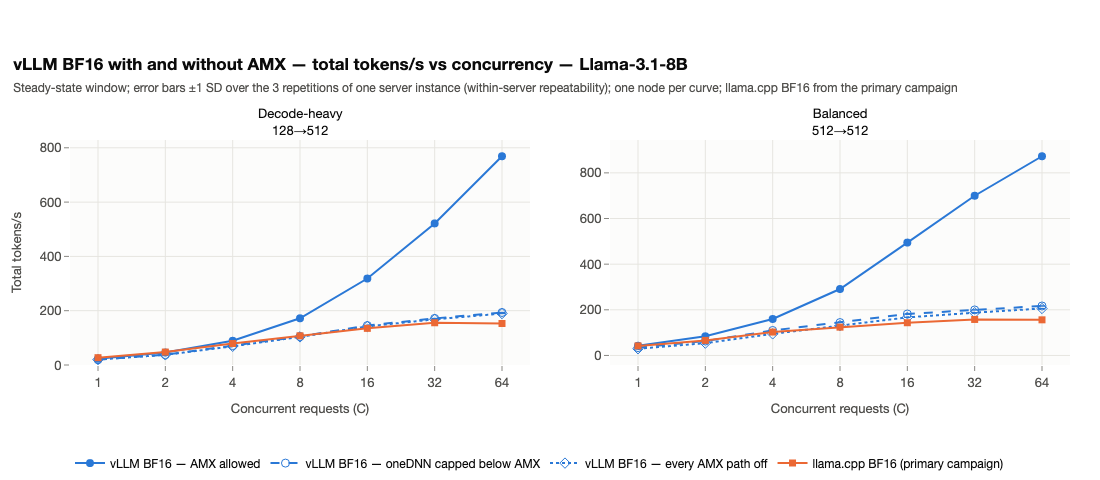

In [5]:
lv_pts = loaders.online_points("amx-ablation", model=registry.primary_model(), include_variants=True)
lv = amx.level_frame(lv_pts)
main = loaders.online_points(model=registry.primary_model())
llama = main[main["configuration_id"] == "llama_cpp_bf16"]
vllm_main = main[main["configuration_id"] == "vllm_bf16"]
fig = plots.ablation_figure(lv, llama[llama["workload"].isin(lv["workload"].unique())],
                            title="vLLM BF16 with and without AMX — total tokens/s vs concurrency — Llama-3.1-8B",
                            subtitle="Steady-state window; error bars ±1 SD over the 3 repetitions of one server instance (within-server repeatability); "
                                     "one node per curve; llama.cpp BF16 from the primary campaign")
fig.show()
export_figure(fig, "amx_ablation_throughput", source=NOTEBOOK,
              caption="vLLM BF16 total tokens/s vs concurrent requests with AMX allowed, with oneDNN capped below AMX and with every AMX path off, for the balanced "
                      "(512→512) and decode-heavy (128→512) workloads; llama.cpp BF16 as reference. Error bars: ±1 SD over the 3 repetitions of one server instance.")

In [6]:
summ = amx.level_summary(lv)
summ["level_label"] = summ["level"].map(amx.LEVEL_LABELS)
display(table(summ.assign(workload=summ["workload"].map(lambda w: registry.workload_label(w, short=True)))
              [["workload", "level_label", "c1", "tput_c_max", "peak_over_c1", "last_doubling_gain", "rel_c1", "rel_c_max"]]
              .rename(columns={"workload": "Workload", "level_label": "Level", "c1": "tok/s at C=1", "tput_c_max": "tok/s at C=64",
                               "peak_over_c1": "Peak ÷ C=1", "last_doubling_gain": "Last doubling (32→64)", "rel_c1": "÷ AMX level, C=1",
                               "rel_c_max": "÷ AMX level, C=64"}),
              {"tok/s at C=1": "{:.1f}", "tok/s at C=64": "{:.0f}", "Peak ÷ C=1": "{:.1f}×", "Last doubling (32→64)": "{:+.0%}",
               "÷ AMX level, C=1": "{:.2f}", "÷ AMX level, C=64": "{:.2f}"}, align="left"))
export_table(summ.drop(columns="level_label"), "amx_ablation_summary")
S = summ.set_index(["workload", "level"])
repro = lv[lv["level"] == "amx"].merge(vllm_main[["workload", "concurrency", "total_tok_s_mean"]], on=["workload", "concurrency"], suffixes=("", "_main"))
repro_dev = repro["total_tok_s_mean"] / repro["total_tok_s_mean_main"] - 1
_p = lv.pivot_table(index=["workload", "concurrency"], columns="level", values="total_tok_s_mean")
both_off_all = _p["noamx_all"] / _p["noamx_gemm"] - 1
both_off = both_off_all[both_off_all.index.get_level_values("concurrency") >= 8].abs()
node_of = lv.groupby(["workload", "level"])["hosts"].first().unstack()
node_spread = repro_dev.abs().max()
show(f"**Nodes.** Each curve ran on one node, and the levels of the balanced workload ran on different nodes ({', '.join(f'{amx.LEVEL_LABELS[l]}: {node_of.loc['balanced', l].split('-')[-1]}' for l in amx.LEVELS)}); "
     f"the AMX level differs from the primary campaign's vLLM BF16 by up to {pct(node_spread, 0, False)} ({rng(repro_dev, pct, nd=1)}; balanced shape, largest at low C). Differences between levels smaller than that "
     f"are therefore not interpreted; effects of 2× and more are.")
show(f"Removing AMX from oneDNN lowers single-request throughput by {rng(1 - S.xs('noamx_gemm', level='level')['rel_c1'], lambda v: pct(v, 0, False))} (decode, balanced; within the node spread above, "
     f"so not read as an AMX effect) and the throughput at C = 64 by {rng(1 - S.xs('noamx_gemm', level='level')['rel_c_max'], lambda v: pct(v, 0, False))}: the scaling factor peak ÷ C=1 falls from "
     f"{rng(S.xs('amx', level='level')['peak_over_c1'], x)} to {rng(S.xs('noamx_gemm', level='level')['peak_over_c1'], x)}, and the last doubling of C adds "
     f"{rng(S.xs('noamx_gemm', level='level')['last_doubling_gain'], pct)} instead of {rng(S.xs('amx', level='level')['last_doubling_gain'], pct)}. "
     f"Switching off vLLM's own AMX kernels as well changes the result by {rng(both_off, lambda v: pct(v, 0, False))} at C ≥ 8 (and up to {pct(both_off_all.abs().max(), 0, False)} at C = 1, within the node spread).")

Workload,Level,tok/s at C=1,tok/s at C=64,Peak ÷ C=1,Last doubling (32→64),"÷ AMX level, C=1","÷ AMX level, C=64"
128→512,AMX allowed,22.6,769,34.1×,+47%,1.00,1.00
128→512,oneDNN capped below AMX,19.6,193,9.9×,+13%,0.87,0.25
128→512,every AMX path off,20.0,189,9.5×,+13%,0.89,0.25
512→512,AMX allowed,42.5,873,20.5×,+25%,1.00,1.00
512→512,oneDNN capped below AMX,34.3,217,6.3×,+9%,0.81,0.25
512→512,every AMX path off,29.4,206,7.0×,+10%,0.69,0.24


**Nodes.** Each curve ran on one node, and the levels of the balanced workload ran on different nodes (AMX allowed: hbm05, oneDNN capped below AMX: hbm06, every AMX path off: hbm01); the AMX level differs from the primary campaign's vLLM BF16 by up to 14% (-2.3%–+13.9%; balanced shape, largest at low C). Differences between levels smaller than that are therefore not interpreted; effects of 2× and more are.

Removing AMX from oneDNN lowers single-request throughput by 13%–19% (decode, balanced; within the node spread above, so not read as an AMX effect) and the throughput at C = 64 by 75%: the scaling factor peak ÷ C=1 falls from 20.5×–34.1× to 6.3×–9.9×, and the last doubling of C adds +9%–+13% instead of +25%–+47%. Switching off vLLM's own AMX kernels as well changes the result by 1%–9% at C ≥ 8 (and up to 14% at C = 1, within the node spread).

## 4. Why: the same batches, a costlier step

If AMX only changed how requests are batched, tokens per step would differ between levels. They do not; what changes is how long a step takes.

In [7]:
chk = amx.batching_check(lv_pts)
hi = chk[chk["concurrency"] == 64]
show(f"Tokens per forward step differ by at most {pct(chk['tokens_per_step_vs_amx'].abs().max(), 1, False)} between levels at any C (vLLM forms the same batches). The step rate relative to the AMX level "
     f"falls from {rng(chk[chk['concurrency'] == 1]['step_rate_vs_amx'], x, nd=2)} at C = 1 to {rng(hi['step_rate_vs_amx'], x, nd=2)} at C = 64, i.e. a step takes "
     f"{rng(1 / hi['step_rate_vs_amx'], x)} as long without AMX at C = 64. Measured AMX busy fraction of the cycles with AMX allowed: "
     f"{rng(lv[lv['level'] == 'amx']['amx_busy_frac_mean'], lambda v: pct(v, 1, False))} (C = 1 to 64); with oneDNN capped "
     f"{pct(lv[lv['level'] == 'noamx_gemm']['amx_busy_frac_mean'].max(), 2, False)} at most; with every path off {pct(lv[lv['level'] == 'noamx_all']['amx_busy_frac_mean'].max(), 1, False)}.")
lat = lv[lv["concurrency"].isin([1, 64])].pivot_table(index=["workload", "concurrency"], columns="level", values=["tpot_s_p50_mean", "ttft_s_p50_mean"])
lat_tab = pd.DataFrame({(m, lvl): lat[(m, lvl)] for m in ("ttft_s_p50_mean", "tpot_s_p50_mean") for lvl in amx.LEVELS}) * 1e3
lat_tab.columns = [f"{'TTFT' if m.startswith('ttft') else 'TPOT'} ms, {amx.LEVEL_LABELS[l]}" for m, l in lat_tab.columns]
display(table(lat_tab.reset_index().assign(workload=lambda d: d["workload"].map(lambda w: registry.workload_label(w, short=True))).rename(columns={"workload": "Workload", "concurrency": "C"}),
              {c: "{:.0f}" for c in lat_tab.columns}, caption="Median latencies at C = 1 and C = 64"))

Tokens per forward step differ by at most 6.1% between levels at any C (vLLM forms the same batches). The step rate relative to the AMX level falls from 0.69×–0.89× at C = 1 to 0.24×–0.25× at C = 64, i.e. a step takes 4.0×–4.3× as long without AMX at C = 64. Measured AMX busy fraction of the cycles with AMX allowed: 0.3%–11.4% (C = 1 to 64); with oneDNN capped 0.05% at most; with every path off 0.0%.

Workload,C,"TTFT ms, AMX allowed","TTFT ms, oneDNN capped below AMX","TTFT ms, every AMX path off","TPOT ms, AMX allowed","TPOT ms, oneDNN capped below AMX","TPOT ms, every AMX path off"
512→512,1,427,1955,2007,46,55,64
512→512,64,585,2546,2625,142,576,607
128→512,1,151,608,593,55,63,61
128→512,64,259,1221,1236,103,412,421


## 5. How much of vLLM's lead over llama.cpp is AMX?

At equal C the lead of vLLM BF16 over llama.cpp BF16 (primary campaign, same weights) is split into the part the AMX ablation removes and the remainder:
lead = [vLLM with AMX ÷ vLLM without AMX] × [vLLM without AMX ÷ llama.cpp]. The decomposition is only meaningful where vLLM actually leads (C ≥ 8), and it uses the
oneDNN-capped level, the setting of the review.

In [8]:
dec = amx.lead_decomposition(lv_pts, llama)
big = dec[dec["concurrency"] >= 16]
top = dec[dec["concurrency"] == 64].set_index("workload")
display(table(top.reset_index().assign(workload=lambda d: d["workload"].map(lambda w: registry.workload_label(w, short=True)))
              [["workload", "vllm_over_llama", "amx_factor", "rest_factor", "amx_log_share"]]
              .rename(columns={"workload": "Workload (C = 64)", "vllm_over_llama": "vLLM ÷ llama.cpp", "amx_factor": "× AMX (vLLM with ÷ without)",
                               "rest_factor": "× rest (vLLM without AMX ÷ llama.cpp)", "amx_log_share": "AMX share of the lead (log)"}),
              {"vLLM ÷ llama.cpp": "{:.2f}×", "× AMX (vLLM with ÷ without)": "{:.2f}×", "× rest (vLLM without AMX ÷ llama.cpp)": "{:.2f}×",
               "AMX share of the lead (log)": "{:.0%}"}, align="left"))
export_table(dec, "amx_lead_decomposition")
show(f"At C = 64 vLLM BF16 delivers {rng(top['vllm_over_llama'], x)} llama.cpp BF16's throughput; the AMX factor is {rng(top['amx_factor'], x)} and what is left without AMX is "
     f"{rng(top['rest_factor'], x)}. In logarithmic terms AMX carries {rng(big['amx_log_share'], lambda v: pct(v, 0, False))} of the lead over C = 16…64 "
     f"(C = 1 is not decomposed: vLLM does not lead there). Without AMX, vLLM is still ahead of llama.cpp from C = {int(dec[dec['rest_factor'] > 1].groupby('workload')['concurrency'].min().max())} upward.")

Workload (C = 64),vLLM ÷ llama.cpp,× AMX (vLLM with ÷ without),× rest (vLLM without AMX ÷ llama.cpp),AMX share of the lead (log)
128→512,5.03×,3.98×,1.26×,85%
512→512,5.59×,4.03×,1.39×,81%


At C = 64 vLLM BF16 delivers 5.0×–5.6× llama.cpp BF16's throughput; the AMX factor is 4.0× and what is left without AMX is 1.3×–1.4×. In logarithmic terms AMX carries 81%–92% of the lead over C = 16…64 (C = 1 is not decomposed: vLLM does not lead there). Without AMX, vLLM is still ahead of llama.cpp from C = 16 upward.

**Interpretation.** *Measured:* with AMX removed, vLLM stops scaling (a plateau near 200 tok/s, against 870 still rising) and its steps take about four times as long at C = 64 while forming the same batches;
AMX busy falls to zero, so the loss is not an artefact of a half-applied ablation. *Measured:* most of vLLM's lead over llama.cpp at high concurrency disappears without AMX, and the lead at C = 1
on short prompts is not due to AMX (it does not exist there). *Inferred:* AMX in the oneDNN GEMMs is the main reason vLLM scales; vLLM's own AMX attention kernel adds little on top (the two ablated levels differ by under 10% at C ≥ 8; the larger differences at C = 1 are within the node spread).
*Not shown:* what part of the remaining 1.3–1.4× lead is scheduling and what is kernel quality, and whether a hand-written AMX kernel in llama.cpp would close the AMX share (section 2 shows its AMX build already helps prompt processing 1.5–2.4× but reaches few percent of the roof).

In [9]:
claims3 = [
    Claim("Without AMX, vLLM's throughput at C = 64 falls below 30% of the AMX level on both workloads", bool((S.xs("noamx_gemm", level="level")["rel_c_max"] < 0.30).all()),
          rng(S.xs("noamx_gemm", level="level")["rel_c_max"], lambda v: pct(v, 0, False))),
    Claim("Without AMX, vLLM scales less than half as far (peak ÷ C=1)", bool((S.xs("noamx_gemm", level="level")["peak_over_c1"] < S.xs("amx", level="level")["peak_over_c1"] / 2).all()),
          f"{rng(S.xs('noamx_gemm', level='level')['peak_over_c1'], x)} vs {rng(S.xs('amx', level='level')['peak_over_c1'], x)}"),
    Claim("The levels form the same batches (tokens per step within 7%)", bool(chk["tokens_per_step_vs_amx"].abs().max() < 0.07), pct(chk["tokens_per_step_vs_amx"].abs().max(), 1, False)),
    Claim("The deepest level has AMX busy exactly zero; the oneDNN-capped level below 0.1% of the cycles",
          bool((lv[lv["level"] == "noamx_all"]["amx_busy_frac_mean"] == 0).all() and (lv[lv["level"] == "noamx_gemm"]["amx_busy_frac_mean"] < 0.001).all()),
          f"{pct(lv[lv['level'] == 'noamx_gemm']['amx_busy_frac_mean'].max(), 3, False)} at most"),
    Claim("Switching off vLLM's own AMX kernels as well changes throughput by under 10% at C ≥ 8", bool((both_off < 0.10).all()), rng(both_off, lambda v: pct(v, 0, False))),
    Claim("AMX carries more than half of vLLM's lead over llama.cpp at C = 16…64", bool((big["amx_log_share"] > 0.5).all()), rng(big["amx_log_share"], lambda v: pct(v, 0, False))),
    Claim("At C ≥ 8 the loss without AMX is at least twice the largest node-to-node difference observed (AMX level vs primary campaign)",
          bool(((1 - lv.pivot_table(index=["workload", "concurrency"], columns="level", values="total_tok_s_mean").pipe(lambda d: d["noamx_gemm"] / d["amx"]))
                [lambda s: s.index.get_level_values("concurrency") >= 8] > 2 * node_spread).all()),
          f"smallest loss {pct((1 - _p['noamx_gemm'] / _p['amx'])[lambda s: s.index.get_level_values('concurrency') >= 8].min(), 0, False)} vs node spread {pct(node_spread, 0, False)}"),
]
display(claims_table(claims3))

Holds,Statement,Evidence (computed)
✓,"Without AMX, vLLM's throughput at C = 64 falls below 30% of the AMX level on both workloads",25%
✓,"Without AMX, vLLM scales less than half as far (peak ÷ C=1)",6.3×–9.9× vs 20.5×–34.1×
✓,The levels form the same batches (tokens per step within 7%),6.1%
✓,The deepest level has AMX busy exactly zero; the oneDNN-capped level below 0.1% of the cycles,0.046% at most
✓,Switching off vLLM's own AMX kernels as well changes throughput by under 10% at C ≥ 8,1%–9%
✓,AMX carries more than half of vLLM's lead over llama.cpp at C = 16…64,81%–92%
✓,At C ≥ 8 the loss without AMX is at least twice the largest node-to-node difference observed (AMX level vs primary campaign),smallest loss 39% vs node spread 14%


## Conclusions

- **Measured (T3.1, verification):** the three vLLM levels do what they claim: AMX allowed (oneDNN `brg_matmul:avx10_1_512_amx`), oneDNN capped (no AMX matmul, a small residue from vLLM's own
  kernels), every AMX path off (counter exactly zero).
- **Measured (T3.1, sweeps):** without AMX in oneDNN's GEMMs vLLM BF16 keeps about 20–25% of its throughput at C = 64 (balanced 873 → 217 tok/s, decode 769 → 193), scales 6–10× instead of 20–34× and
  takes about four times as long per step while forming the same batches. Switching off its own AMX kernels as well changes little at C ≥ 8. The levels ran on different nodes, so effects below about 15% (the node spread seen) are not interpreted. AMX carries about 80–85% (logarithmic share) of vLLM's lead over llama.cpp BF16 at C = 64.
- **Measured (T3.2):** llama.cpp's AMX build processes Q8_0 prompts 1.5–2.4× faster than its AVX-512 build while reaching only a few percent of the AMX INT8 roof.
- **Interpretation:** AMX is not wasted in llama.cpp but is far from saturated, consistent with "kernel efficiency, not AMX availability" as the engine difference of notebooks 06 and 08.

## Limitations

- Prompt processing only, one model (8B), two passes of three samples; no decode, no batched or served runs with the AVX-512 build.
- The AVX-512 build has the same source and flags apart from AMX; the check is the CMake cache, not the binaries' hashes.
- vLLM sweeps (T3.1): two workloads (balanced, decode-heavy), BF16 only, one node and one server instance per curve (error bars show within-server repeatability, not node-to-node spread; the AMX level reproduces the primary campaign within a few percent).
- The ablation changes which kernels run, not only whether AMX is used: the AVX-512 BF16 code of oneDNN and vLLM is a different implementation, so "without AMX" means "with the fallback kernels", not "the same kernels slower".
- The decomposition of the lead takes the llama.cpp BF16 reference from the primary campaign (other nodes and days) and ignores any interaction between the AMX and non-AMX factors. are not in this notebook yet; only the verification of the levels is.